# 04 — Cohort retention

**Question:** of the customers who first bought in a given month, what share came back in each of the following months?

**Method:** classic acquisition-cohort analysis.
1. Cohort = month of a customer's **first** delivered order (by `customer_unique_id`).
2. For every later order, compute the month offset from the cohort month.
3. Retention(cohort, k) = customers with an order in month k ÷ cohort size.

**Why it matters:** RFM (notebook 03) showed only 3% of customers ever repeat. Cohorts tell us *whether that is improving over time* and *how fast* customers go quiet, which decides whether retention spend is worth it.

Cohorts are limited to 2017-01 → 2018-08 (partial months excluded) and offsets to 12 months.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from viz_style import *

P = Path("../data/processed")
orders    = pd.read_csv(P / "orders.csv", parse_dates=["order_purchase_timestamp"])
customers = pd.read_csv(P / "customers.csv")

df = (orders[orders.is_delivered]
        .merge(customers[["customer_id", "customer_unique_id"]], on="customer_id"))
df["order_month"] = df.order_purchase_timestamp.dt.to_period("M")
df["cohort"]      = df.groupby("customer_unique_id").order_month.transform("min")
df["offset"]      = (df.order_month - df.cohort).apply(lambda x: x.n)

df = df[(df.cohort >= "2017-01") & (df.cohort <= "2018-08")]
print(f"{len(df):,} delivered orders, {df.customer_unique_id.nunique():,} customers in {df.cohort.nunique()} cohorts")

96,200 delivered orders, 93,094 customers in 20 cohorts


## 1. Cohort matrix

In [2]:
cohort_counts = (df.groupby(["cohort", "offset"]).customer_unique_id.nunique()
                   .unstack(fill_value=0))
cohort_size = cohort_counts[0]
retention = cohort_counts.divide(cohort_size, axis=0) * 100
retention = retention.loc[:, retention.columns <= 12]

# Cells beyond the data horizon (cohort month + offset > 2018-08) are not yet observable -> NaN, not 0
last = pd.Period("2018-08", "M")
for c in retention.index:
    for k in retention.columns:
        if c + k > last:
            retention.loc[c, k] = np.nan

retention.round(2).head(6)

offset,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort,,,,,,,,,,,,,
2017-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,0.00,0.42,0.14,0.70
2017-02,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12
2017-03,100.0,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20
2017-04,100.0,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04
2017-05,100.0,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23
2017-06,100.0,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16


In [3]:
# Average retention curve (weighted by cohort size, only observable cells)
obs = retention.notna()
weighted = (retention.fillna(0) * cohort_size.values[:, None]).sum() / (obs * cohort_size.values[:, None]).sum()
curve = weighted.drop(0).round(3)
curve.to_frame("avg_retention_pct").T

offset,1,2,3,4,5,6,7,8,9,10,11,12
avg_retention_pct,0.483,0.337,0.256,0.256,0.226,0.232,0.208,0.204,0.16,0.252,0.22,0.168


## 2. Heat map

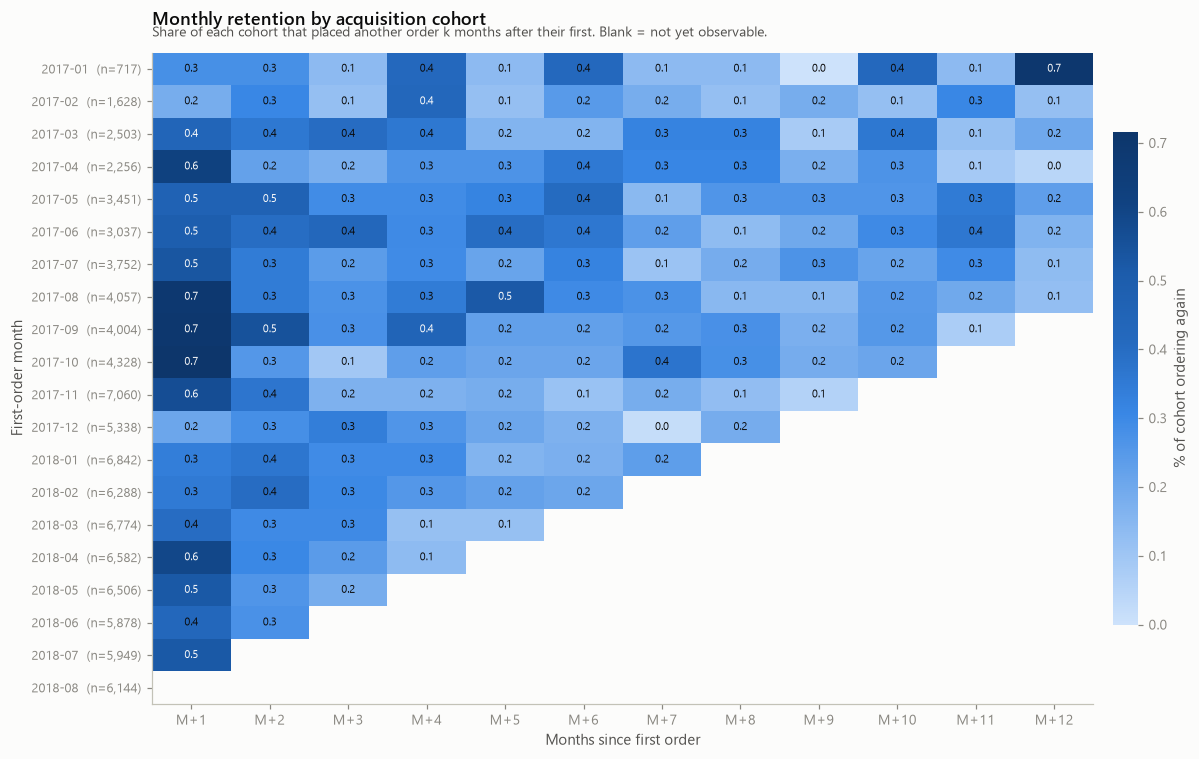

In [4]:
fig, ax = plt.subplots(figsize=(11, 7))
data = retention.drop(columns=0)
im = ax.imshow(data.values, cmap=CMAP_SEQ, aspect="auto", vmin=0, vmax=np.nanmax(data.values))
ax.set_xticks(range(data.shape[1])); ax.set_xticklabels([f"M+{k}" for k in data.columns])
ax.set_yticks(range(data.shape[0])); ax.set_yticklabels([f"{c}  (n={cohort_size[c]:,})" for c in data.index], fontsize=8.5)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5,
                    color=SURFACE if v > np.nanmax(data.values) * 0.6 else INK)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.set_label("% of cohort ordering again", color=INK2); cb.outline.set_visible(False)
finish(ax, "Monthly retention by acquisition cohort", "Share of each cohort that placed another order k months after their first. Blank = not yet observable.",
       xlabel="Months since first order", ylabel="First-order month")
plt.tight_layout(); save(fig, "04_cohort_heatmap"); plt.show()

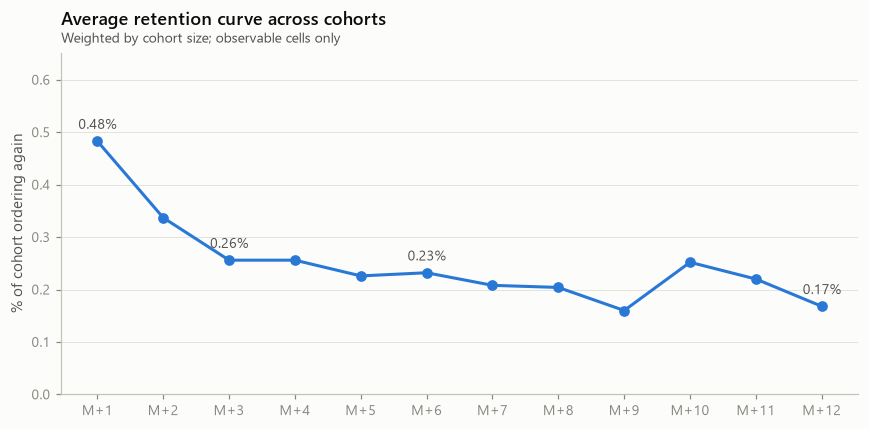

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve.index, curve.values, marker="o", color=BLUE)
for k, v in curve.items():
    if k in (1, 3, 6, 12):
        ax.annotate(f"{v:.2f}%", (k, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=INK2)
ax.set_xticks(curve.index); ax.set_xticklabels([f"M+{k}" for k in curve.index])
ax.set_ylim(0, curve.max() * 1.35)
finish(ax, "Average retention curve across cohorts", "Weighted by cohort size; observable cells only", ylabel="% of cohort ordering again")
plt.tight_layout(); save(fig, "04_retention_curve"); plt.show()

## 3. Is retention improving for newer cohorts?

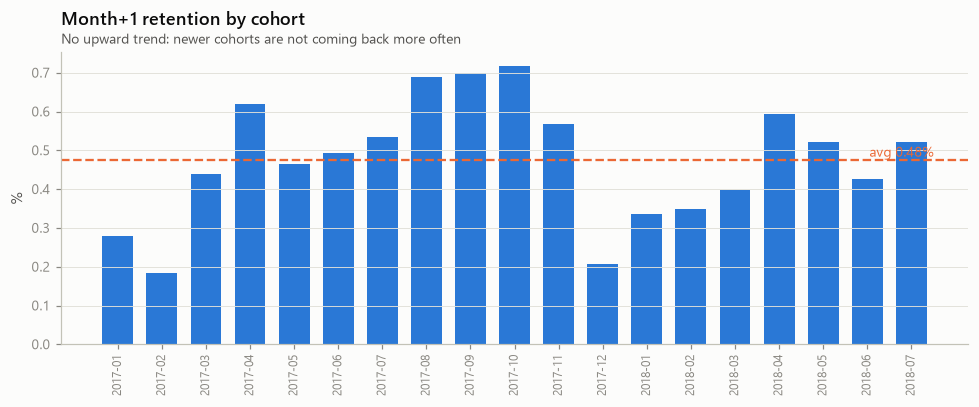

M+1 retention: first 6 cohorts avg 0.41%  |  last 6 cohorts avg 0.47%


In [6]:
m1 = retention[1].dropna()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(len(m1)), m1.values, color=BLUE, width=0.7)
ax.set_xticks(range(len(m1))); ax.set_xticklabels([str(c) for c in m1.index], rotation=90, fontsize=8)
ax.axhline(m1.mean(), color=ORANGE, lw=1.5, ls="--"); ax.text(len(m1)-0.5, m1.mean(), f" avg {m1.mean():.2f}%", color=ORANGE, va="bottom", ha="right", fontsize=9)
finish(ax, "Month+1 retention by cohort", "No upward trend: newer cohorts are not coming back more often", ylabel="%")
plt.tight_layout(); save(fig, "04_m1_by_cohort"); plt.show()
print(f"M+1 retention: first 6 cohorts avg {m1.iloc[:6].mean():.2f}%  |  last 6 cohorts avg {m1.iloc[-6:].mean():.2f}%")

## 4. Overall repeat rate and export

In [7]:
per_cust = df.groupby("customer_unique_id").order_id.nunique()
repeat_rate = (per_cust > 1).mean() * 100
# time to second order for those who did come back
s = df.sort_values("order_purchase_timestamp")
s["prev_ts"] = s.groupby("customer_unique_id").order_purchase_timestamp.shift(1)
s["order_n"] = s.groupby("customer_unique_id").cumcount() + 1
gap = (s.loc[s.order_n == 2, "order_purchase_timestamp"] - s.loc[s.order_n == 2, "prev_ts"]).dt.days
print(f"Repeat-purchase rate (2017-01..2018-08 cohorts): {repeat_rate:.2f}%")
print(f"Of repeaters, median days to 2nd order: {gap.median():.0f}; 25%/75%: {gap.quantile(.25):.0f}/{gap.quantile(.75):.0f}; "
      f"{(gap <= 30).mean():.0%} reorder within 30 days, {(gap <= 90).mean():.0%} within 90")

retention.round(3).to_csv(P / "cohort_retention_matrix.csv")
# long form for Power BI matrix visual
long = retention.stack().rename("retention_pct").reset_index()
long.columns = ["cohort", "months_since_first", "retention_pct"]
long["cohort"] = long.cohort.astype(str); long["cohort_size"] = long.cohort.map(cohort_size.rename(index=str))
long.to_csv(P / "cohort_retention_long.csv", index=False)
print("exported cohort_retention_matrix.csv and cohort_retention_long.csv")

Repeat-purchase rate (2017-01..2018-08 cohorts): 2.99%
Of repeaters, median days to 2nd order: 28; 25%/75%: 0/125; 51% reorder within 30 days, 68% within 90
exported cohort_retention_matrix.csv and cohort_retention_long.csv


## So what

- **Retention is near zero and flat.** Fewer than 1 in 100 customers in any cohort orders again in the following month, and the curve never recovers; newer cohorts are no better than older ones. Olist's growth in 2017–18 was entirely new-customer acquisition.
- **This is plausible for this kind of marketplace, not necessarily a failure.** Olist sells *through* big retail sites: the shopper is a Walmart/Extra customer who often never sees the Olist brand, buys one-off items (gifts, home goods) and has no account relationship to return to. Industry e-commerce repeat rates of 20–30% assume a branded store; the comparable here is marketplace-side sellers, whose repeat rates are also low.
- **The window to act is short.** Among the few who do reorder, half do so within the first few weeks. That argues for a *post-delivery* intervention (review request + category recommendation + second-order voucher in week 1–4) rather than a quarterly CRM programme. Combined with notebook 05, the single most powerful retention lever is likely to be simply delivering the first order on time.

**What a business should do:** (1) measure retention per *channel partner* and per *seller* — a blended 3% hides pockets of loyalty; (2) run the post-delivery sequence as an A/B test on the Potential Loyalist segment first; (3) treat on-time delivery as a retention KPI, not just an ops KPI.